# Week 09 — Qwen2.5-7B-Instruct baseline

Qwen generates answers on Modal, and the notebook saves the responses and evaluation results locally.

## 1. Local dependencies

Install the libraries below in your local Jupyter environment. Modal authentication and project files are described in [README.md](README.md).


In [1]:
%pip install modal==1.6.4 pandas==2.2.3 matplotlib==3.10.1 python-dotenv

Note: you may need to restart the kernel to use updated packages.


## 2. Configuration

Run three trials with seeds 42, 43 and 44. Each trial answers the same 125 questions, producing one response per question: 125 responses per trial and 375 responses in total.


In [2]:
from pathlib import Path
import os
import sys

MODAL_PROFILE = "neu-info5100-oak-spr-2025" # jianan2315 or neu-info5100-oak-spr-2025
GPU = "A100-80GB"
RUN_NAME = "qwen7b-direct-paper-judge-v1"
REUSE_ANSWERS_FROM = "qwen7b-direct-sequential-v1"  # Copy answers into a new run for regrading; None to resume.
QUESTION_LIMIT = 125
MODEL_REVISION = "a09a35458c702b33eeacc393d103063234e8bc28"
TRIAL_SEEDS = [42, 43, 44]
TEMPERATURE = 0.7
MAX_NEW_TOKENS = 512
JUDGE_MODEL = "gpt-4o-2024-08-06"  # Frozen GPT-4o snapshot; never silently replace it.
RUN_INFERENCE = True          # Reuse local answers; True generates new answers on Modal.
RUN_JUDGE = True                 # Independent switch; requires your OpenAI API key.

# Just restart kernel if u encounter any issue without changing code.
os.environ["MODAL_PROFILE"] = MODAL_PROFILE
HERE = Path.cwd()
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))

import pandas as pd
from IPython.display import display, Markdown
from baseline import evaluation as ev
from baseline import results

benchmark = results.load_benchmark(HERE / "bamboogle.json")
questions = benchmark["rows"][:QUESTION_LIMIT]

SETTINGS = dict(question_limit=QUESTION_LIMIT, seeds=TRIAL_SEEDS,
                temperature=TEMPERATURE, max_new_tokens=MAX_NEW_TOKENS, judge_model=JUDGE_MODEL,
                model_revision=MODEL_REVISION, gpu=GPU)
OUTPUT_ROOT = HERE / "outputs"
RUN_DIR = OUTPUT_ROOT / RUN_NAME
display(pd.DataFrame([SETTINGS]).drop(columns=["seeds"]).assign(trial_seeds=str(TRIAL_SEEDS)))
print("Local result directory:", RUN_DIR)

,question_limit,temperature,max_new_tokens,judge_model,model_revision,gpu,trial_seeds
0,125,0.7,512,gpt-4o-2024-08-06,a09a35458c702b33eeacc393d103063234e8bc28,A100-80GB,"[42, 43, 44]"


Local result directory: /mnt/c/Users/flywi/Desktop/gitRepos/neu-self-improve-ai/week_09/outputs/qwen7b-direct-paper-judge-v1


## 3. Sequential inference

Load the model once, then run seeds 42, 43 and 44 in order. The following cells save the answers and display generation time and GPU memory usage.

With `RUN_INFERENCE=False`, `REUSE_ANSWERS_FROM` copies saved answers into the new `RUN_NAME` and clears scores in the copy for regrading. The source run is unchanged. To resume this new run, set `REUSE_ANSWERS_FROM=None`.


In [3]:
if not RUN_INFERENCE:
    if REUSE_ANSWERS_FROM:
        RUN_DIR, manifest = results.prepare_regrading(
            OUTPUT_ROOT, RUN_NAME, REUSE_ANSWERS_FROM, JUDGE_MODEL)
    else:
        manifest = results.read_json(RUN_DIR / "manifest.json")
    saved = results.read_json(RUN_DIR / "sequential_response.json")
    records = results.response_records(saved)
    print("Using saved answers.")
else:
    import time
    from baseline.config import MODEL_ID, SYSTEM_PROMPT

    RUN_DIR, manifest = results.prepare_run(OUTPUT_ROOT, RUN_NAME, SETTINGS, SYSTEM_PROMPT, MODEL_ID)
    from baseline.modal_app import app, answer_trials
    result_path = RUN_DIR / "sequential_response.json"
    display(Markdown(f"**Running {len(TRIAL_SEEDS)} sequential trials on one {GPU}.**"))
    started = time.perf_counter()
    with app.run():
        output = answer_trials.with_options(gpu=GPU).remote(
            [q["question"] for q in questions], TRIAL_SEEDS,
            manifest["protocol"]["settings"]["model_revision"], TEMPERATURE, MAX_NEW_TOKENS)
    saved = {"client_call_seconds": time.perf_counter() - started, "output": output}
    saved = results.prepare_response(saved, manifest, questions)
    records = results.response_records(saved)
    total = len(questions) * len(TRIAL_SEEDS)
    if len(records) != total:
        raise RuntimeError("Inference returned an incomplete set of answers.")
    results.write_json(result_path, saved)
    display(Markdown(f"**Inference complete:** {len(records)}/{total} responses saved locally."))
    display(pd.DataFrame(records)[["trial", "seed", "question", "response"]].tail(5))
    print("Local result:", result_path)
    print("Judging is a separate local step.")

**Running 3 sequential trials on one A100-80GB.**

**Inference complete:** 375/375 responses saved locally.

,trial,seed,question,response
370,3,44,When was the composer of Carol of the Bells born?,"The composer of ""Carol of the Bells"" is Mykola..."
371,3,44,Who is the father of the scientist at MIT that...,"To answer this question, we need to identify t..."
372,3,44,Who was the mother of the emperor of Japan dur...,To determine the mother of the Japanese empero...
373,3,44,Which element has an atomic number that is dou...,To determine the element with an atomic number...
374,3,44,What was the motto of the Olympics that had Fu...,The Olympics with the Fuwa mascots were the 20...


Local result: /mnt/c/Users/flywi/Desktop/gitRepos/neu-self-improve-ai/week_09/outputs/qwen7b-direct-paper-judge-v1/sequential_response.json
Judging is a separate local step.


In [4]:
timing = saved["output"]
display(pd.DataFrame([{
    "seed": r["seed"], "actual_gpu": timing["gpu"],
    "generation_seconds": r.get("generation_seconds"),
    "peak_gpu_reserved_GiB": r.get("peak_gpu_reserved_gib"),
} for r in timing["outputs"]]))

,seed,actual_gpu,generation_seconds,peak_gpu_reserved_GiB
0,42,NVIDIA A100-SXM4-80GB,11.714022,17.244141
1,43,NVIDIA A100-SXM4-80GB,10.877215,17.261719
2,44,NVIDIA A100-SXM4-80GB,14.290259,17.734375


## 4. GPT-4o scoring

Set `OPENAI_API_KEY` in `.env` beside this notebook and set `RUN_JUDGE=True`. GPT-4o checks whether each generated final answer is equivalent to a reference answer and returns a correctness decision with a brief explanation.

The scoring instructions follow Appendix E.3, with JSON output and support for alternative reference answers. Each request uses the instructions saved in the run manifest.


In [5]:
if not RUN_JUDGE:
    print("Judging is off. Set RUN_JUDGE=True in configuration when ready.")
else:
    from dotenv import dotenv_values
    pending = [r for r in records if r.get("judge") is None]
    if pending:
        api_key = dotenv_values(HERE / ".env", encoding="utf-8-sig").get("OPENAI_API_KEY")
        judged = len(records) - len(pending)
        judge_status = display(Markdown(f"**Grading progress:** {judged}/{len(records)} answers graded."), display_id=True)
        judge_preview = display(pd.DataFrame(columns=["question_id", "correct", "analysis"]), display_id=True)
        try:
            for record in pending:
                record["judge"] = ev.judge_answer(
                    record["question"], record["reference_answers"], record["response"],
                    manifest["protocol"]["settings"]["judge_model"], api_key,
                    prompt=manifest["protocol"]["judge_prompt"])
                results.save_judgment(RUN_DIR, record["trial"], record["question_id"], record["judge"])
                judged += 1
                judge_status.update(Markdown(f"**Grading progress:** {judged}/{len(records)} grading results saved."))
                judge_preview.update(pd.DataFrame([{
                    "question_id": record["question_id"], "correct": record["judge"]["correct"],
                    "analysis": record["judge"]["analysis"]}]))
        finally:
            del api_key
            records = results.load_records(RUN_DIR)
    else:
        print("All saved responses have already been judged; no API requests made.")

**Grading progress:** 375/375 grading results saved.

,question_id,correct,analysis
0,bamboogle-125,True,The final answer extracted from the Model Resp...


## 5. Trial results and accuracy

This section summarizes the answers and grading decisions from the preceding steps. A trial's accuracy is reported after all its questions have answers and scores. Missing scores are not counted as incorrect answers. A reduced question set is labelled as a subset.

The final mean is the arithmetic mean of trial accuracies. The reported standard deviation is the sample standard deviation across trials, in percentage points.


### Qwen2.5-7B-Instruct · Direct answering

Benchmark scope: full_125
Model revision: a09a35458c702b33eeacc393d103063234e8bc28
Saved responses: 375 | length-limited: 0


,trial,seed,expected,generated,judged,correct,accuracy_percent,status
0,1,42,125,125,125,44,35.2,complete
1,2,43,125,125,125,49,39.2,complete
2,3,44,125,125,125,48,38.4,complete


**Mean accuracy: 37.60%** · sample standard deviation: 2.12 percentage points

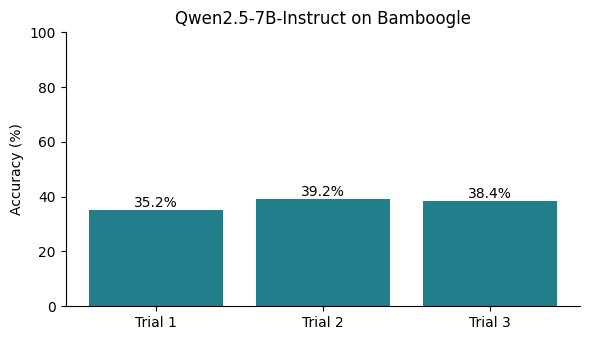

In [6]:
report = ev.summary(records, manifest)
display(Markdown("### Qwen2.5-7B-Instruct · Direct answering"))
print("Benchmark scope:", report["benchmark_scope"])
print("Model revision:", report["model_revision"])
print("Saved responses:", len(records), "| length-limited:", report["length_limited_responses"])
trial_table = pd.DataFrame(report["trials"])
display(trial_table)
if report["complete"]:
    mean = report["mean_accuracy_percent"]
    std = report["sample_std_percentage_points"]
    message = f"**Mean accuracy: {mean:.2f}%**"
    if std is not None:
        message += f" · sample standard deviation: {std:.2f} percentage points"
    display(Markdown(message))
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.bar([f"Trial {t}" for t in trial_table.trial], trial_table.accuracy_percent, color="#237e8c")
    ax.set(ylabel="Accuracy (%)", ylim=(0, 100), title="Qwen2.5-7B-Instruct on Bamboogle")
    ax.spines[["top", "right"]].set_visible(False)
    for i, value in enumerate(trial_table.accuracy_percent):
        ax.text(i, value + 1, f"{value:.1f}%", ha="center")
    fig.tight_layout()
    plt.show()
else:
    display(Markdown("**Evaluation is incomplete. Overall accuracy is not yet reported.**"))

## Saved files

Paths below are relative to the notebook folder. Replace `<RUN_NAME>` with the configured run name.

| Relative path | Contents |
| --- | --- |
| `outputs/<RUN_NAME>/manifest.json` | Initial experiment settings: model ID and revision, dataset name, question count, seeds, generation settings, requested GPU and judge model. Also contains the instructions given to Qwen and the scoring instructions given to GPT-4o. |
| `outputs/<RUN_NAME>/sequential_response.json` | Results grouped into three trials. Each trial contains its number, seed, generation statistics, peak reserved GPU memory and 125 answer records. Each answer record contains the question ID, question, reference answers, generated answer, token counts, stopping reason and a `judge` field for the grading result. Shared information, including the actual GPU, library versions, input statistics and overall inference timings, is stored once outside the trial groups. |

Scoring uses the questions, reference answers and generated answers stored in `outputs/<RUN_NAME>/sequential_response.json`. Each grading result is saved in the corresponding answer's `judge` field in that same file, including correctness, an explanation and API response metadata. The results section calculates accuracy from these saved grading decisions; it does not create a separate statistics file.

For a regraded run, `manifest.json` also records `source_run`. Its generation settings and timing measurements describe the original inference; its scoring instructions and judge model describe the new grading run.
